Sample size: 500
Number of purchases: 45
Sample conversion rate: 9.00%
Bootstrap 95% CI: [6.60%, 11.60%]


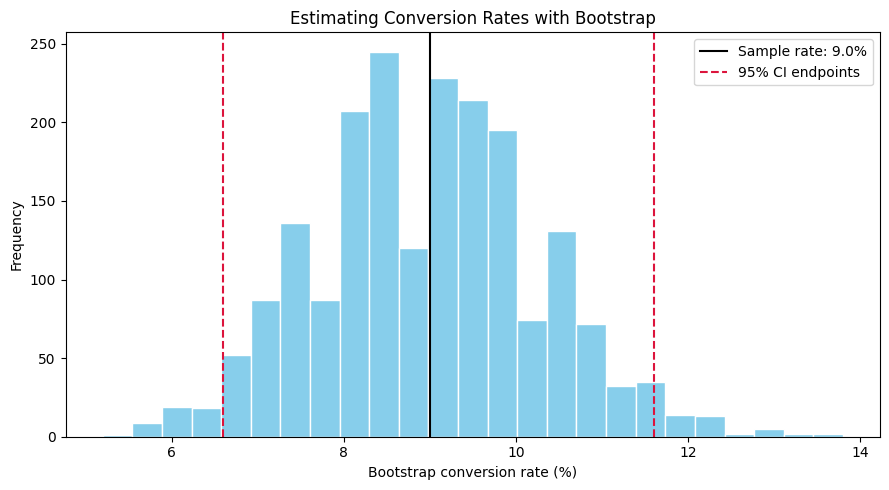

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Fix the random seed so the results are reproducible
rng = np.random.default_rng(42)

# Basic settings
true_p = 0.10
n = 500
B = 2000

# Simulate one sample of visitors
sample = rng.binomial(1, true_p, size=n)
sample_rate = sample.mean()

# Bootstrap: repeatedly resample FROM THIS SAME SAMPLE
bootstrap_samples = rng.choice(sample, size=(B, n), replace=True)
bootstrap_rates = bootstrap_samples.mean(axis=1)

# Percentile bootstrap 95% confidence interval
ci_low, ci_high = np.percentile(bootstrap_rates, [2.5, 97.5])

print(f"Sample size: {n}")
print(f"Number of purchases: {sample.sum()}")
print(f"Sample conversion rate: {sample_rate:.2%}")
print(f"Bootstrap 95% CI: [{ci_low:.2%}, {ci_high:.2%}]")

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    bootstrap_rates * 100,
    bins=25,
    color="skyblue",
    edgecolor="white"
)

ax.axvline(
    sample_rate * 100,
    color="black",
    label=f"Sample rate: {sample_rate:.1%}"
)
ax.axvline(
    ci_low * 100,
    color="crimson",
    linestyle="--",
    label="95% CI endpoints"
)
ax.axvline(ci_high * 100, color="crimson", linestyle="--")

ax.set(
    title="Estimating Conversion Rates with Bootstrap",
    xlabel="Bootstrap conversion rate (%)",
    ylabel="Frequency"
)
ax.legend()
fig.tight_layout()
fig.savefig("figure1.png", dpi=200, bbox_inches="tight")
plt.show()

Number of independent samples: 1000
Intervals containing the true rate: 952
Estimated coverage: 95.2%


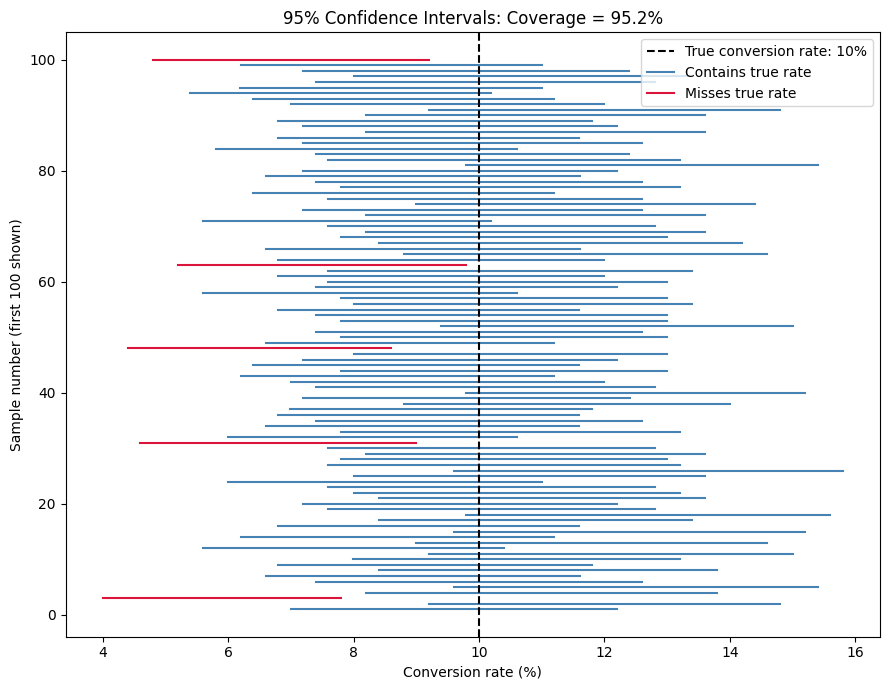

In [2]:
# Number of independent experiments
M = 1000

# Bootstrap resamples within each experiment
B_coverage = 1000

lower_bounds = np.empty(M)
upper_bounds = np.empty(M)

for i in range(M):
    # Draw a NEW sample from the population
    new_sample = rng.binomial(1, true_p, size=n)

    # Bootstrap this new sample
    resamples = rng.choice(
        new_sample,
        size=(B_coverage, n),
        replace=True
    )
    rates = resamples.mean(axis=1)

    lower_bounds[i], upper_bounds[i] = np.percentile(
        rates, [2.5, 97.5]
    )

# Does each interval contain the true parameter?
covered = (
    (lower_bounds <= true_p) &
    (true_p <= upper_bounds)
)

coverage = covered.mean()

print(f"Number of independent samples: {M}")
print(f"Intervals containing the true rate: {covered.sum()}")
print(f"Estimated coverage: {coverage:.1%}")

# Display the first 100 intervals
fig, ax = plt.subplots(figsize=(9, 7))

for i in range(100):
    color = "steelblue" if covered[i] else "crimson"

    ax.plot(
        [lower_bounds[i] * 100, upper_bounds[i] * 100],
        [i + 1, i + 1],
        color=color,
        linewidth=1.5
    )

ax.axvline(
    true_p * 100,
    color="black",
    linestyle="--",
    label="True conversion rate: 10%"
)

# Empty lines create clear legend labels
ax.plot([], [], color="steelblue", label="Contains true rate")
ax.plot([], [], color="crimson", label="Misses true rate")

ax.set(
    title=f"95% Confidence Intervals: Coverage = {coverage:.1%}",
    xlabel="Conversion rate (%)",
    ylabel="Sample number (first 100 shown)"
)
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig("figure2.png", dpi=200, bbox_inches="tight")
plt.show()

Observed purchases: 60 out of 500
Observed conversion rate: 12.0%
Simulated p-value: 0.0807
Rejection region: purchases >= 62
Decision: Do not reject H0 at the 5% significance level.


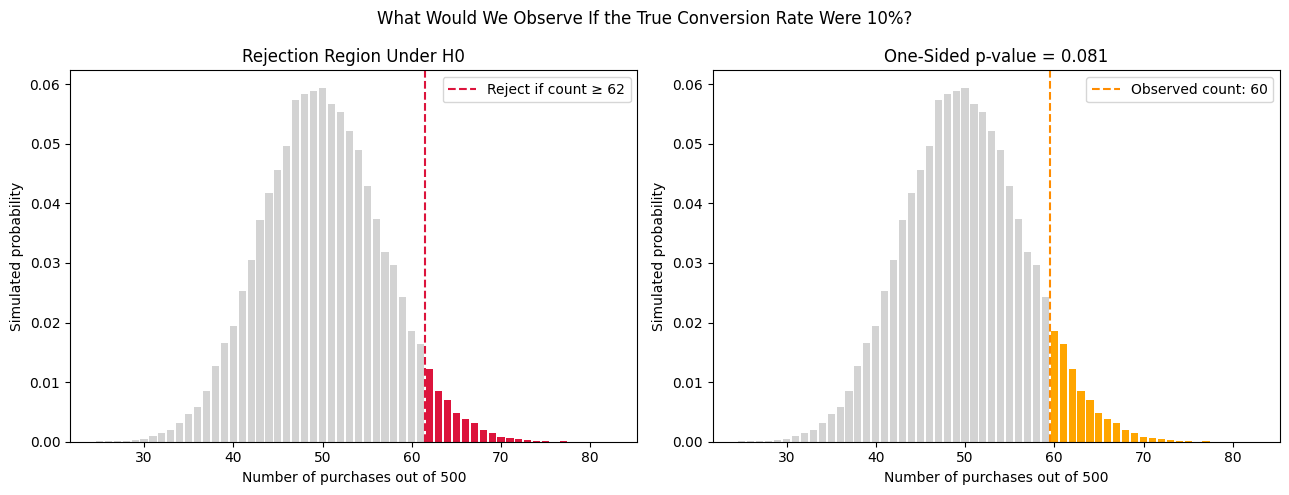

In [3]:
# A separate illustrative observation
observed_purchases = 60
observed_rate = observed_purchases / n

null_p = 0.10
alpha = 0.05
S = 50000

# Generate the test statistic under H0
null_counts = rng.binomial(n, null_p, size=S)

# Simulated one-sided p-value:
# probability of observing 60 or more purchases under H0
p_value = (
    np.sum(null_counts >= observed_purchases) + 1
) / (S + 1)

# Find the smallest count whose simulated upper-tail
# probability is no greater than alpha
frequencies = np.bincount(null_counts, minlength=n + 1)
tail_probabilities = np.cumsum(frequencies[::-1])[::-1] / S

critical_count = np.where(
    tail_probabilities <= alpha
)[0][0]

print(f"Observed purchases: {observed_purchases} out of {n}")
print(f"Observed conversion rate: {observed_rate:.1%}")
print(f"Simulated p-value: {p_value:.4f}")
print(f"Rejection region: purchases >= {critical_count}")

if p_value <= alpha:
    print("Decision: Reject H0 at the 5% significance level.")
else:
    print("Decision: Do not reject H0 at the 5% significance level.")

# Plot the same null distribution in two panels
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x = np.arange(null_counts.min(), null_counts.max() + 1)
probabilities = frequencies[x] / S

# Left panel: rejection region
axes[0].bar(
    x,
    probabilities,
    color=np.where(x >= critical_count, "crimson", "lightgray")
)
axes[0].axvline(
    critical_count - 0.5,
    color="crimson",
    linestyle="--",
    label=f"Reject if count ≥ {critical_count}"
)
axes[0].set(
    title="Rejection Region Under H0",
    xlabel="Number of purchases out of 500",
    ylabel="Simulated probability"
)
axes[0].legend()

# Right panel: p-value
axes[1].bar(
    x,
    probabilities,
    color=np.where(x >= observed_purchases, "orange", "lightgray")
)
axes[1].axvline(
    observed_purchases - 0.5,
    color="darkorange",
    linestyle="--",
    label=f"Observed count: {observed_purchases}"
)
axes[1].set(
    title=f"One-Sided p-value = {p_value:.3f}",
    xlabel="Number of purchases out of 500",
    ylabel="Simulated probability"
)
axes[1].legend()

fig.suptitle("What Would We Observe If the True Conversion Rate Were 10%?")
fig.tight_layout()
fig.savefig("figure3.png", dpi=200, bbox_inches="tight")
plt.show()

In [4]:
print("===== Results for the Blog =====")
print(f"True conversion rate: {true_p:.1%}")
print(f"Sample size: {n}")
print(f"Initial sample conversion rate: {sample_rate:.2%}")
print(f"Bootstrap CI: [{ci_low:.2%}, {ci_high:.2%}]")
print(f"Coverage across {M} samples: {coverage:.1%}")
print(f"Hypothesis-test observed rate: {observed_rate:.1%}")
print(f"One-sided p-value: {p_value:.4f}")
print(f"Rejection threshold: {critical_count} purchases")

===== Results for the Blog =====
True conversion rate: 10.0%
Sample size: 500
Initial sample conversion rate: 9.00%
Bootstrap CI: [6.60%, 11.60%]
Coverage across 1000 samples: 95.2%
Hypothesis-test observed rate: 12.0%
One-sided p-value: 0.0807
Rejection threshold: 62 purchases
